# TP #4 — Ensemble Learning
**Apprentissage Automatique Avancé** — Prof. Abdelouahab Moussaoui

- **Partie I** : bagging, forêts aléatoires et boosting sur la base **Digits** (10 % des données pour l'apprentissage, 90 % pour le test, comme dans le sujet)
- **Partie II** : forêts aléatoires sur **Iris** et sur **MNIST**

> **Remarques de compatibilité.** Dans le sujet, `AdaBoostClassifier(base_estimator=...)` : ce paramètre a été renommé **`estimator`** dans les versions récentes de scikit-learn (et `base_estimator` supprimé), on utilise donc `estimator=`.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from sklearn import tree
from sklearn.datasets import load_digits, load_iris
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier,
                              ExtraTreesClassifier, AdaBoostClassifier)
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.metrics import confusion_matrix, classification_report

np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.precision', 4)

digits = load_digits()
X, y = digits.data, digits.target
print(X.shape, y.shape)

def resume(acc, nom):
    return pd.Series({'moyenne': acc.mean(), 'écart-type': acc.std(ddof=1), 'variance': acc.var(ddof=1),
                      'min': acc.min(), 'max': acc.max()}, name=nom)

def une_experience(make_model, seed, test_size=0.9):
    Xa, Xt, ya, yt = train_test_split(X, y, test_size=test_size, random_state=seed)
    return make_model(seed).fit(Xa, ya).score(Xt, yt)

def acc_sur_tirages(make_model, n=100, test_size=0.9):
    return np.array(Parallel(n_jobs=-1)(delayed(une_experience)(make_model, s, test_size) for s in range(n)))

def courbe_n_estimators(make_model, ns, n_tirages=20):
    # make_model doit créer un modèle avec warm_start=True : on ajoute des arbres au même modèle
    def un_tirage(seed):
        Xa, Xt, ya, yt = train_test_split(X, y, test_size=0.9, random_state=seed)
        m = make_model(seed); out = []
        for n in ns:
            m.set_params(n_estimators=n); m.fit(Xa, ya); out.append(m.score(Xt, yt))
        return out
    return np.array(Parallel(n_jobs=-1)(delayed(un_tirage)(s) for s in range(n_tirages)))

def tracer_courbe(ax, ns, res, label):
    m, s = res.mean(0), res.std(0, ddof=1)
    ax.plot(ns, m, 'o-', ms=3, label=label); ax.fill_between(ns, m - s, m + s, alpha=.15)

def n_plateau(ns, res, tol=0.005):
    m = res.mean(0); cible = m[-1] - tol
    return int(np.array(ns)[np.argmax(m >= cible)])

(1797, 64) (1797,)


---
# Partie I — Apprendre la technique
## Bagging
### Classifieur de référence : un arbre de décision (ensemble à 1 modèle)

In [2]:
# Sur toute la base : accuracy = 1 sur l'apprentissage (l'arbre mémorise les données)
clf = tree.DecisionTreeClassifier(random_state=0).fit(X, y)
print("Accuracy (apprentissage, toute la base) :", clf.score(X, y))

# 10 % pour l'apprentissage, 90 % pour le test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.90, random_state=0)
print("Taille apprentissage / test :", len(X_train), "/", len(X_test))

clf = tree.DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
print("Arbre : accuracy apprentissage =", clf.score(X_train, y_train))
print("Arbre : accuracy test          =", round(clf.score(X_test, y_test), 4))

Accuracy (apprentissage, toute la base) : 1.0
Taille apprentissage / test : 179 / 1618
Arbre : accuracy apprentissage = 1.0
Arbre : accuracy test          = 0.6724


### Question 1 — Variance de l'accuracy sur 100 tirages apprentissage/test

(30 s)


,moyenne,écart-type,variance,min,max
arbre seul,0.6889,0.0297,0.0009,0.6088,0.7553
bagging (200 arbres),0.8751,0.0197,0.0004,0.8288,0.9197


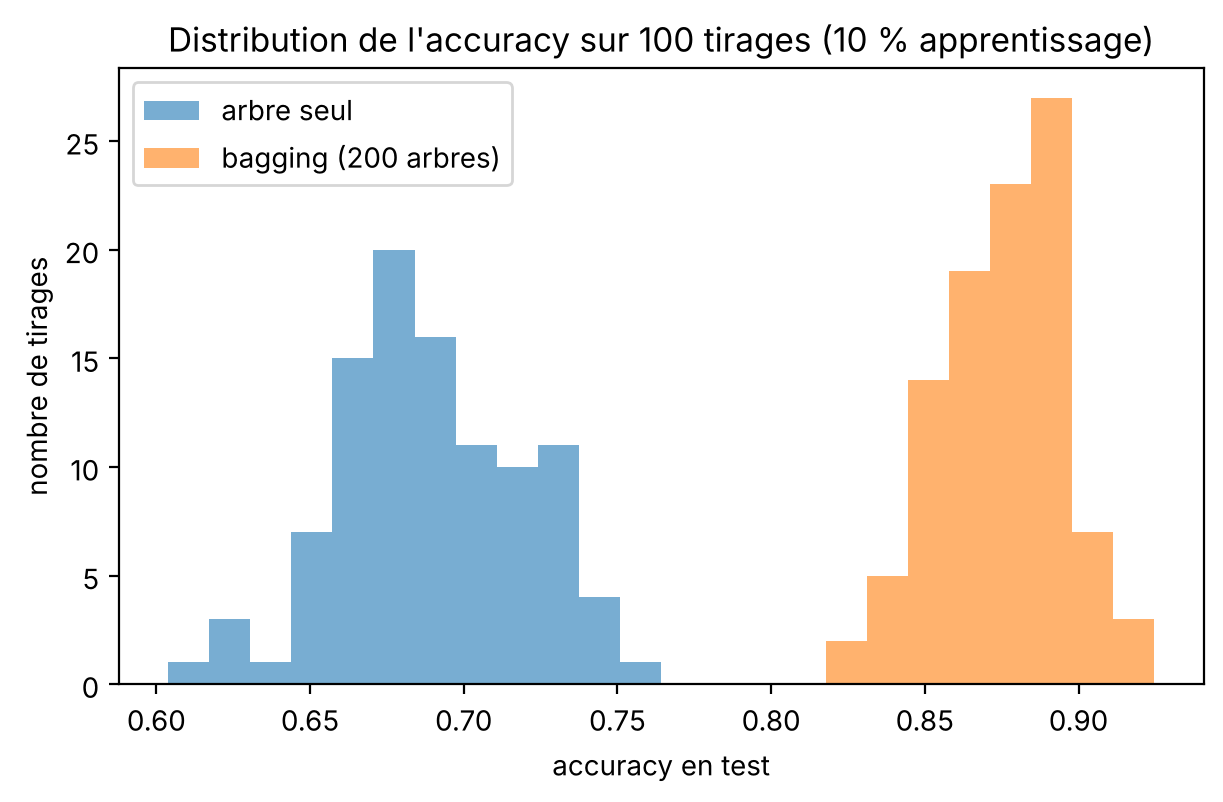

Rapport des variances arbre / bagging : 2.26


In [3]:
t0 = time.time()
acc_dt   = acc_sur_tirages(lambda s: tree.DecisionTreeClassifier(random_state=s))
acc_bag  = acc_sur_tirages(lambda s: BaggingClassifier(n_estimators=200, random_state=s))
print(f"({time.time()-t0:.0f} s)")
display(pd.concat([resume(acc_dt, 'arbre seul'), resume(acc_bag, 'bagging (200 arbres)')], axis=1).T)

plt.figure(figsize=(7, 4))
bins = np.linspace(min(acc_dt.min(), acc_bag.min()) - .005, max(acc_dt.max(), acc_bag.max()) + .005, 25)
plt.hist(acc_dt, bins=bins, alpha=.6, label='arbre seul')
plt.hist(acc_bag, bins=bins, alpha=.6, label='bagging (200 arbres)')
plt.xlabel("accuracy en test"); plt.ylabel("nombre de tirages"); plt.legend()
plt.title("Distribution de l'accuracy sur 100 tirages (10 % apprentissage)"); plt.show()
print(f"Rapport des variances arbre / bagging : {acc_dt.var(ddof=1) / acc_bag.var(ddof=1):.2f}")

**Commentaire.** Ici la variance est celle de l'accuracy **d'un tirage apprentissage/test à l'autre** (100 découpages, 179 exemples d'apprentissage seulement) :

| | moyenne | écart-type | variance | min – max |
|---|---|---|---|---|
| arbre seul | 68,9 % | 2,97 points | 9·10⁻⁴ | 60,9 % – 75,5 % |
| bagging (200 arbres) | 87,5 % | 1,97 points | 4·10⁻⁴ | 82,9 % – 92,0 % |

- Un **arbre de décision seul est un estimateur très instable** (forte variance) : avec peu de données d'apprentissage, il mémorise l'échantillon (accuracy = 1 en apprentissage) et son résultat dépend beaucoup des images tirées. Une accuracy isolée ne signifie pas grand-chose ; il faut donner une moyenne et un écart-type.
- Le **bagging réduit la variance** (rapport ≈ 2,3) et **améliore fortement la précision moyenne (+18,6 points)** : en moyennant 200 arbres appris sur des échantillons bootstrap différents, on lisse les erreurs individuelles qui s'annulent en partie.

### Question 2 — Accuracy vs `n_estimators`

(20 s)


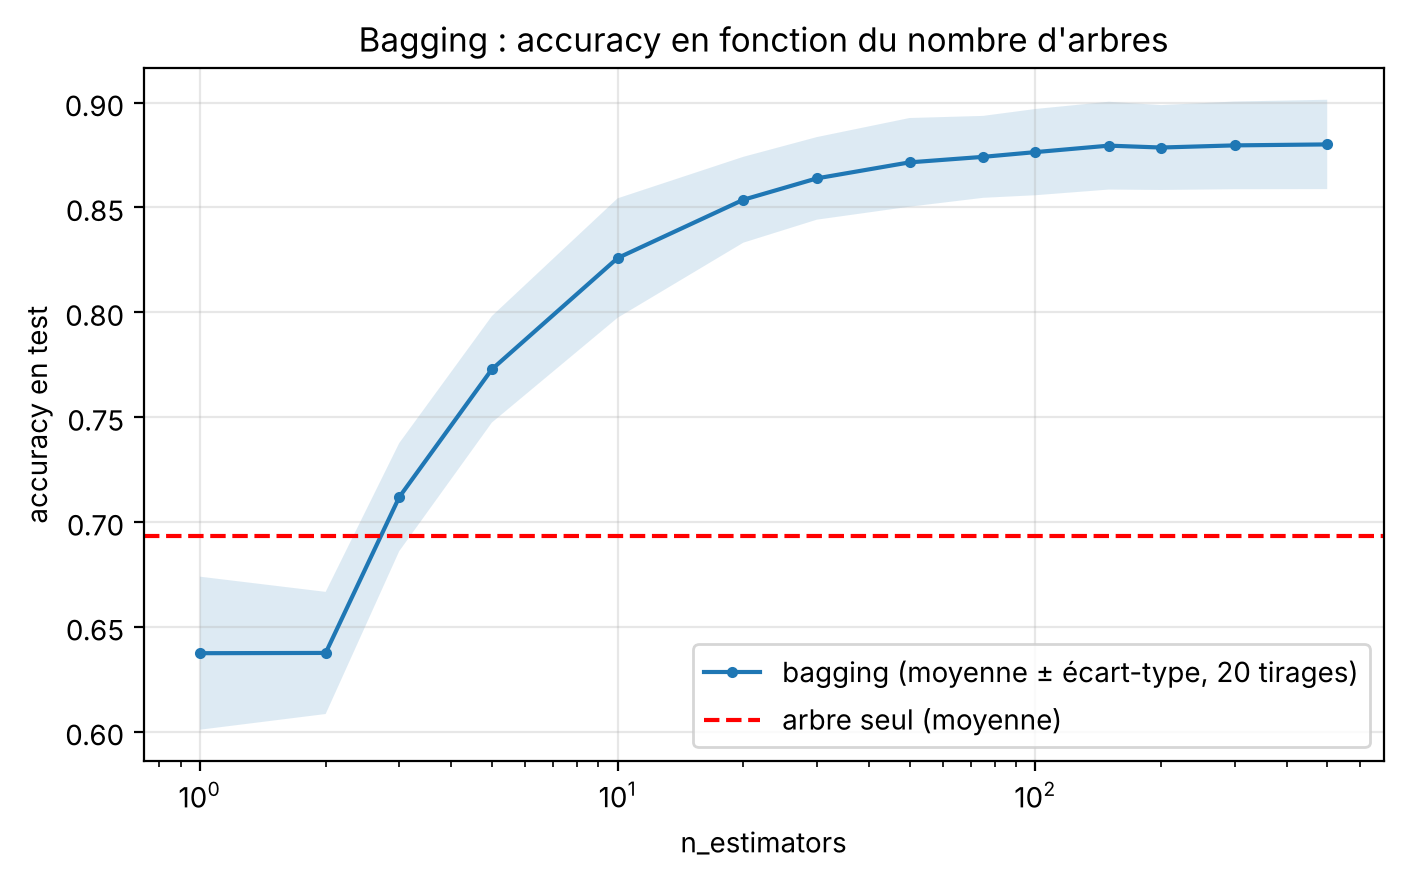

n_estimators,1,2,3,5,10,20,30,50,75,100,150,200,300,500
accuracy moyenne,0.6374,0.6375,0.7118,0.7728,0.8258,0.8536,0.8638,0.8715,0.8741,0.8764,0.8794,0.8786,0.8796,0.8800
écart-type,0.0365,0.0291,0.0258,0.0254,0.0285,0.0205,0.0197,0.0212,0.0195,0.0206,0.0209,0.0202,0.0209,0.0213


Premier n dont la moyenne est à moins de 0,5 point de la valeur obtenue pour 500 arbres : 100


In [4]:
ns = [1, 2, 3, 5, 10, 20, 30, 50, 75, 100, 150, 200, 300, 500]
t0 = time.time()
res_bag = courbe_n_estimators(lambda s: BaggingClassifier(random_state=s, warm_start=True), ns, n_tirages=20)
print(f"({time.time()-t0:.0f} s)")

fig, ax = plt.subplots(figsize=(8, 4.5))
tracer_courbe(ax, ns, res_bag, "bagging (moyenne ± écart-type, 20 tirages)")
ax.axhline(acc_dt[:20].mean(), c='r', ls='--', label="arbre seul (moyenne)")
ax.set_xscale('log'); ax.set_xlabel("n_estimators"); ax.set_ylabel("accuracy en test"); ax.grid(alpha=.3); ax.legend()
ax.set_title("Bagging : accuracy en fonction du nombre d'arbres"); plt.show()

display(pd.DataFrame({'n_estimators': ns, 'accuracy moyenne': res_bag.mean(0), 'écart-type': res_bag.std(0, ddof=1)}).set_index('n_estimators').T)
print("Premier n dont la moyenne est à moins de 0,5 point de la valeur obtenue pour 500 arbres :", n_plateau(ns, res_bag))

**Constat.**
- Un seul arbre bootstrap ne fait que **63,7 %** (plus faible que l'arbre sur toutes les données, 68,9 %, car il ne voit qu'environ 63 % d'exemples distincts).
- L'accuracy **monte très vite** avec le nombre d'arbres : 82,6 % à 10 arbres, 86,4 % à 30, 87,6 % à 100, puis **se stabilise vers 88,0 %** (500 arbres).
- À partir de **≈ 100 arbres** (à moins de 0,5 point de la valeur finale), les gains sont négligeables. Il n'y a **pas de surapprentissage** quand on ajoute des arbres : la courbe ne redescend pas, on paie seulement en temps de calcul.
- Le palier est fixé par le **biais** des arbres et par leur **corrélation** (ils sont tous entraînés sur les mêmes variables), pas par leur nombre.

### Question 3 — Variation de `max_samples` et `max_features` (GridSearchCV)

In [5]:
frac = [0.1, 0.25, 0.5, 0.75, 1.0]
grille = {'max_samples': frac, 'max_features': frac}
t0 = time.time()
gs = GridSearchCV(BaggingClassifier(n_estimators=100, random_state=0), grille, cv=5, n_jobs=-1)
gs.fit(X_train, y_train)
print(f"GridSearchCV (5 plis, sur les 179 exemples d'apprentissage) en {time.time()-t0:.0f} s")
print("Meilleurs paramètres :", gs.best_params_, "| score CV =", round(gs.best_score_, 4))
print("Score test correspondant (1 tirage) :", round(gs.score(X_test, y_test), 4))

cv_tab = pd.DataFrame(gs.cv_results_).pivot(index='param_max_samples', columns='param_max_features', values='mean_test_score')
cv_tab.index.name, cv_tab.columns.name = 'max_samples', 'max_features'
print("\nScore de validation croisée (lignes : max_samples, colonnes : max_features)")
display(cv_tab)

GridSearchCV (5 plis, sur les 179 exemples d'apprentissage) en 9 s
Meilleurs paramètres : {'max_features': 0.5, 'max_samples': 0.75} | score CV = 0.911
Score test correspondant (1 tirage) : 0.9098

Score de validation croisée (lignes : max_samples, colonnes : max_features)


max_features,0.10,0.25,0.50,0.75,1.00
max_samples,,,,,
0.10,0.7822,0.8162,0.8270,0.8216,0.8046
0.25,0.7878,0.8771,0.8771,0.8771,0.8660
0.50,0.8544,0.8770,0.8940,0.8713,0.8771
0.75,0.8379,0.8827,0.9110,0.8771,0.8605
1.00,0.8490,0.8825,0.8941,0.8603,0.8490


(25 s)  Accuracy test moyenne sur 10 tirages


max_features,0.10,0.25,0.50,0.75,1.00
max_samples,,,,,
0.10,0.7062,0.7588,0.7655,0.7544,0.7716
0.25,0.8035,0.8599,0.8669,0.8620,0.8648
0.50,0.8328,0.8857,0.8886,0.8844,0.8829
0.75,0.8486,0.8980,0.8954,0.8922,0.8871
1.00,0.8499,0.9025,0.9020,0.8941,0.8864


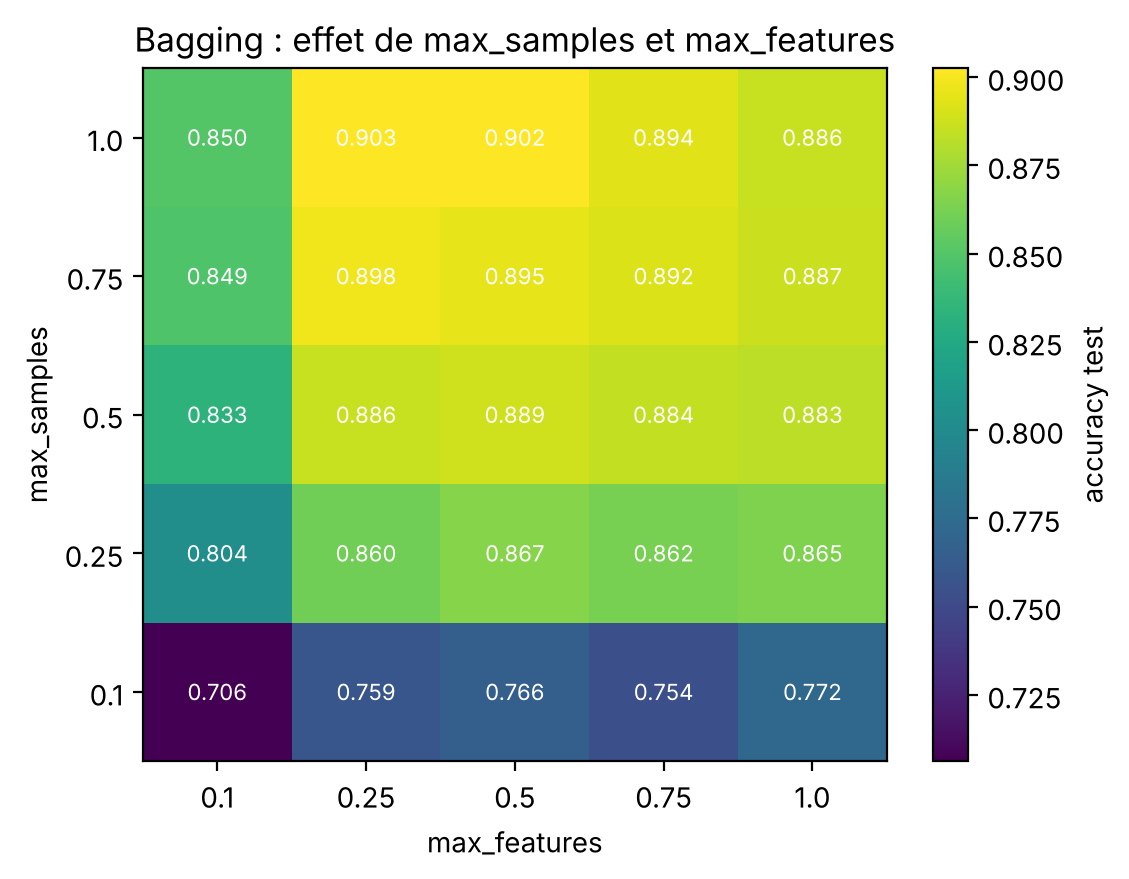

Meilleur couple (moyenne sur 10 tirages) : max_samples = 1.0, max_features = 0.25 -> 0.9025


In [6]:
# Vue plus robuste : accuracy en test moyennée sur 10 tirages apprentissage/test pour chaque couple
def une_combi(ms, mf):
    return acc_sur_tirages_serie(lambda s: BaggingClassifier(n_estimators=100, max_samples=ms, max_features=mf, random_state=s), 10)

def acc_sur_tirages_serie(make_model, n):
    return np.mean([une_experience(make_model, s) for s in range(n)])

t0 = time.time()
vals = Parallel(n_jobs=-1)(delayed(une_combi)(ms, mf) for ms in frac for mf in frac)
heat = pd.DataFrame(np.array(vals).reshape(len(frac), len(frac)), index=frac, columns=frac)
heat.index.name, heat.columns.name = 'max_samples', 'max_features'
print(f"({time.time()-t0:.0f} s)  Accuracy test moyenne sur 10 tirages")
display(heat)

plt.figure(figsize=(6, 4.5))
plt.imshow(heat.values, origin='lower', cmap='viridis', aspect='auto')
plt.xticks(range(5), frac); plt.yticks(range(5), frac)
plt.xlabel("max_features"); plt.ylabel("max_samples"); plt.colorbar(label='accuracy test')
for i in range(5):
    for j in range(5):
        plt.text(j, i, f"{heat.values[i, j]:.3f}", ha='center', va='center', color='w', fontsize=8)
plt.title("Bagging : effet de max_samples et max_features"); plt.show()
i, j = np.unravel_index(np.argmax(heat.values), heat.shape)
print(f"Meilleur couple (moyenne sur 10 tirages) : max_samples = {frac[i]}, max_features = {frac[j]} -> {heat.values[i, j]:.4f}")

**Commentaire.**
- **GridSearchCV** (5 plis sur les 179 exemples d'apprentissage) retient `max_samples = 0,75`, `max_features = 0,5` (score CV 91,1 %, test 91,0 % sur ce tirage). Mais avec si peu de données, cette recherche est **bruitée** : plusieurs cases sont à moins de 1–2 points les unes des autres, ce qui est du niveau de l'écart-type d'un tirage (≈ 2 points).
- La carte moyennée sur **10 tirages** est plus fiable : meilleur couple `max_samples = 1,0`, `max_features = 0,25` (**90,3 %**), mais tout le **plateau `max_features` ∈ [0,25 ; 0,5] avec `max_samples` ≥ 0,5** donne 88,6 % à 90,3 %.
- **Valeurs trop faibles = mauvais résultats** : `max_samples = 0,1` (≈ 18 images par arbre) donne 71–77 % et `max_features = 0,1` (6 variables) donne 71–85 % : les arbres deviennent trop faibles.
- Par rapport au bagging par défaut (`max_samples = 1`, `max_features = 1` : **88,6 %**, 100 arbres), le meilleur réglage ne gagne qu'**environ 1,6 point**. Tirer un sous-ensemble de variables (≈ 25–50 %) **décorrèle les arbres** et est utile ; c'est justement l'idée des forêts aléatoires.

## Forêts aléatoires
10 % des données pour l'apprentissage et 90 % pour le test, comme précédemment.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.90, random_state=0)
clf_rf = RandomForestClassifier(n_estimators=200, random_state=0).fit(X_train, y_train)
y_pred = clf_rf.predict(X_test)
print("Forêt aléatoire (200 arbres) : accuracy test =", round(clf_rf.score(X_test, y_test), 4))

Forêt aléatoire (200 arbres) : accuracy test = 0.9333


### Question 1 — Comparaison avec le bagging (200 arbres)

In [8]:
bag200 = BaggingClassifier(n_estimators=200, random_state=0).fit(X_train, y_train)
dt0 = tree.DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
print(f"Arbre seul         : {dt0.score(X_test, y_test):.4f}")
print(f"Bagging (200)      : {bag200.score(X_test, y_test):.4f}")
print(f"Forêt aléatoire(200): {clf_rf.score(X_test, y_test):.4f}")

Arbre seul         : 0.6724
Bagging (200)      : 0.8832
Forêt aléatoire(200): 0.9333


**Commentaire.** Sur ce tirage : arbre seul **67,2 %**, bagging (200 arbres) **88,3 %**, forêt aléatoire (200 arbres) **93,3 %**. À nombre d'arbres égal, la forêt aléatoire est **nettement meilleure** que le bagging (+5 points ici, +3,7 points en moyenne sur 100 tirages, voir Q2).

**Explication.** La forêt ajoute une randomisation supplémentaire : à **chaque nœud**, le meilleur découpage n'est cherché que sur un sous-ensemble de variables (`max_features='sqrt'`, soit 8 variables sur 64). Les arbres sont ainsi **moins corrélés** entre eux, et la variance d'une moyenne d'arbres diminue d'autant plus que la corrélation est faible.

### Question 2 — Variance de l'accuracy sur 100 tirages

(13 s)


,moyenne,écart-type,variance,min,max
arbre seul,0.6889,0.0297,0.0009,0.6088,0.7553
bagging (200),0.8751,0.0197,0.0004,0.8288,0.9197
forêt aléatoire (200),0.9123,0.0147,0.0002,0.8677,0.9413


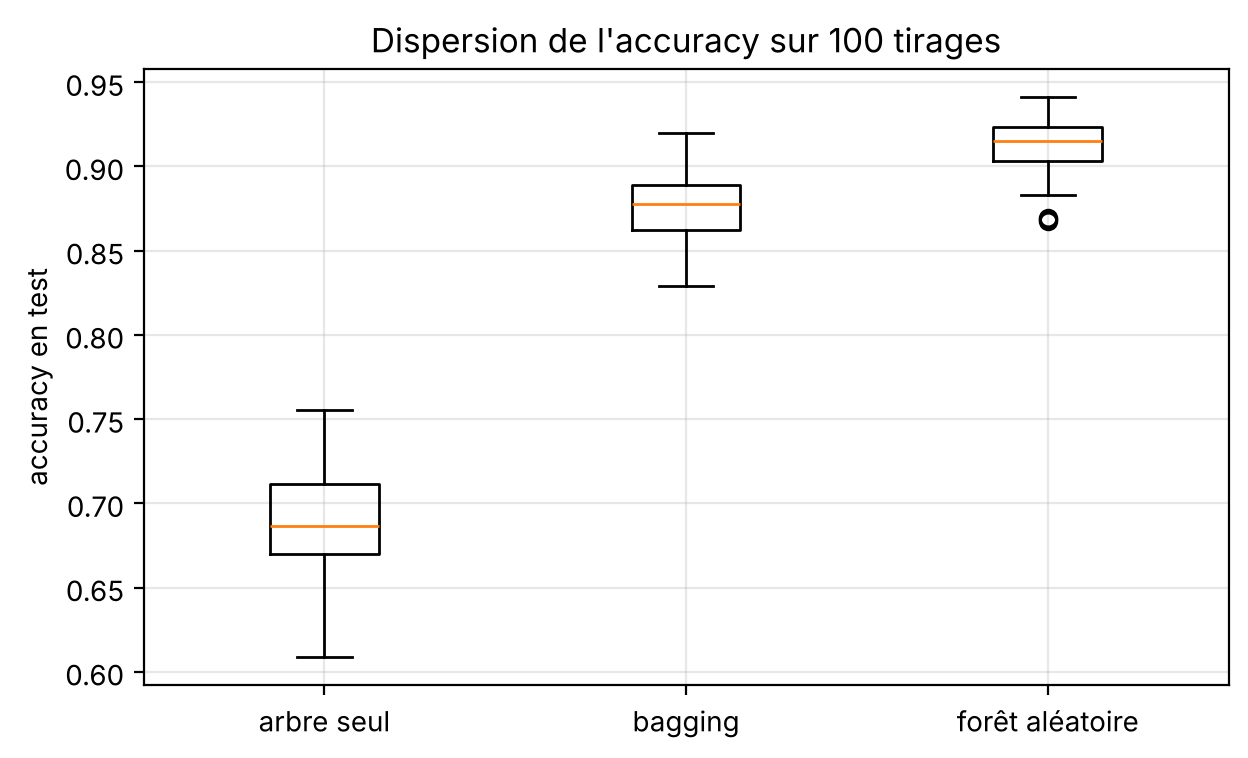

Rapport des variances bagging / forêt : 1.79
Différence appariée forêt - bagging : moyenne = +0.0372, forêt meilleure dans 100 tirages, égalité dans 0, moins bonne dans 0


In [9]:
t0 = time.time()
acc_rf = acc_sur_tirages(lambda s: RandomForestClassifier(n_estimators=200, random_state=s))
print(f"({time.time()-t0:.0f} s)")
display(pd.concat([resume(acc_dt, 'arbre seul'), resume(acc_bag, 'bagging (200)'), resume(acc_rf, 'forêt aléatoire (200)')], axis=1).T)

plt.figure(figsize=(7, 4))
plt.boxplot([acc_dt, acc_bag, acc_rf], tick_labels=['arbre seul', 'bagging', 'forêt aléatoire'])
plt.ylabel("accuracy en test"); plt.title("Dispersion de l'accuracy sur 100 tirages"); plt.grid(alpha=.3); plt.show()
print(f"Rapport des variances bagging / forêt : {acc_bag.var(ddof=1) / acc_rf.var(ddof=1):.2f}")
# Les 100 tirages sont identiques pour les trois méthodes (mêmes seeds) : comparaison appariée
diff = acc_rf - acc_bag
print(f"Différence appariée forêt - bagging : moyenne = {diff.mean():+.4f}, forêt meilleure dans {(diff > 0).sum()} tirages, égalité dans {(diff == 0).sum()}, moins bonne dans {(diff < 0).sum()}")

**Constat (100 mêmes tirages pour les trois méthodes) :**

| | moyenne | écart-type | variance |
|---|---|---|---|
| arbre seul | 68,9 % | 2,97 points | 9·10⁻⁴ |
| bagging (200) | 87,5 % | 1,97 points | 4·10⁻⁴ |
| forêt aléatoire (200) | 91,2 % | 1,47 points | 2·10⁻⁴ |

- La variance est divisée par **≈ 1,8** entre le bagging et la forêt (par ≈ 4 entre l'arbre seul et la forêt) : chaque étape (arbre → bagging → forêt) **améliore la précision moyenne et réduit la variabilité**.
- La comparaison est appariée : la forêt fait **mieux que le bagging dans les 100 tirages** (+3,7 points en moyenne), ce n'est donc pas un effet du hasard.

### Question 3 — Accuracy vs `n_estimators`

(7 s)


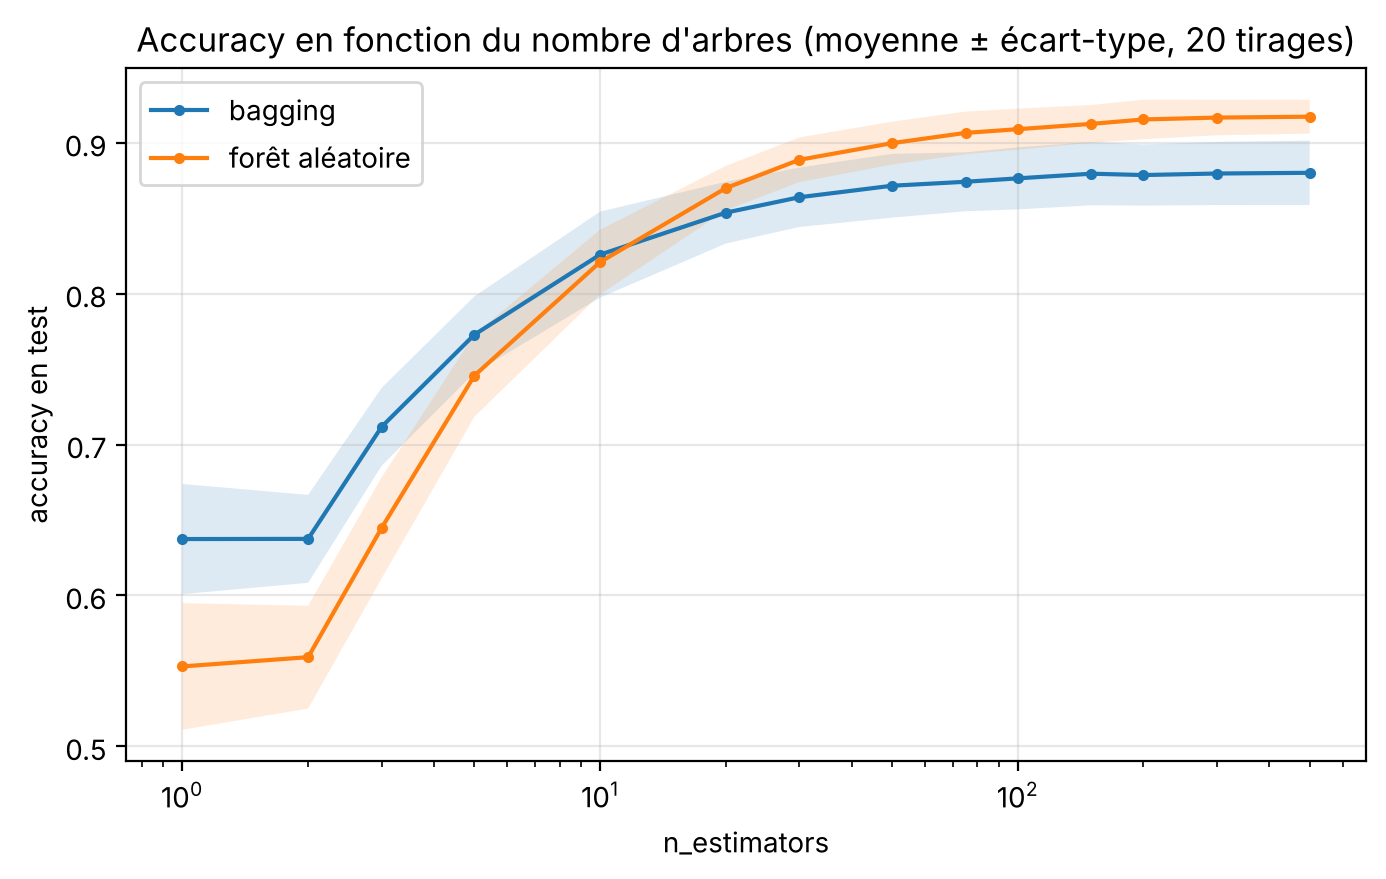

n_estimators,1,2,3,5,10,20,30,50,75,100,150,200,300,500
bagging,0.6374,0.6375,0.7118,0.7728,0.8258,0.8536,0.8638,0.8715,0.8741,0.8764,0.8794,0.8786,0.8796,0.8800
forêt aléatoire,0.5530,0.5591,0.6448,0.7456,0.8209,0.8699,0.8887,0.8997,0.9065,0.9089,0.9125,0.9154,0.9166,0.9172


Forêt : premier n à moins de 0,5 point de la valeur à 500 arbres : 150
Bagging : idem : 100


In [10]:
t0 = time.time()
res_rf = courbe_n_estimators(lambda s: RandomForestClassifier(random_state=s, warm_start=True), ns, n_tirages=20)
print(f"({time.time()-t0:.0f} s)")

fig, ax = plt.subplots(figsize=(8, 4.5))
tracer_courbe(ax, ns, res_bag, "bagging")
tracer_courbe(ax, ns, res_rf, "forêt aléatoire")
ax.set_xscale('log'); ax.set_xlabel("n_estimators"); ax.set_ylabel("accuracy en test"); ax.grid(alpha=.3); ax.legend()
ax.set_title("Accuracy en fonction du nombre d'arbres (moyenne ± écart-type, 20 tirages)"); plt.show()

display(pd.DataFrame({'n_estimators': ns, 'bagging': res_bag.mean(0), 'forêt aléatoire': res_rf.mean(0)}).set_index('n_estimators').T)
print("Forêt : premier n à moins de 0,5 point de la valeur à 500 arbres :", n_plateau(ns, res_rf))
print("Bagging : idem :", n_plateau(ns, res_bag))

**Constat.**
- Un seul arbre de forêt est **plus faible** qu'un seul arbre de bagging (55,3 % contre 63,7 %), car il n'a le droit qu'à 8 variables par découpage. Les deux courbes se croisent vers **10–20 arbres**, puis la forêt passe devant : 87,0 % à 20 arbres, 88,9 % à 30, 90,0 % à 50, 90,9 % à 100, 91,5 % à 200 et **91,7 %** à 500.
- **On n'améliore plus (à moins de 0,5 point près) à partir d'environ 150 arbres** (100 pour le bagging) ; au-delà de 200 arbres, les gains sont inférieurs à 0,3 point. Comme pour le bagging, il n'y a pas de surapprentissage : plus d'arbres ne dégrade pas le résultat.
- La forêt a besoin de **plus d'arbres** que le bagging pour se stabiliser (ses arbres sont individuellement plus faibles), mais son **palier est plus haut** (91,7 % contre 88,0 %).

### Question 4 — ExtraTreesClassifier vs RandomForestClassifier

(10 s)


,moyenne,écart-type,variance,min,max
forêt aléatoire (200),0.9123,0.0147,0.0002,0.8677,0.9413
extra-trees (200),0.9303,0.0123,0.0002,0.8894,0.9567


Différence appariée extra-trees - forêt : moyenne = +0.0180, extra-trees meilleurs dans 99 tirages, égalité 0, moins bons 1


Temps d'apprentissage forêt aléatoire : 0.214 s


Temps d'apprentissage extra-trees     : 0.153 s


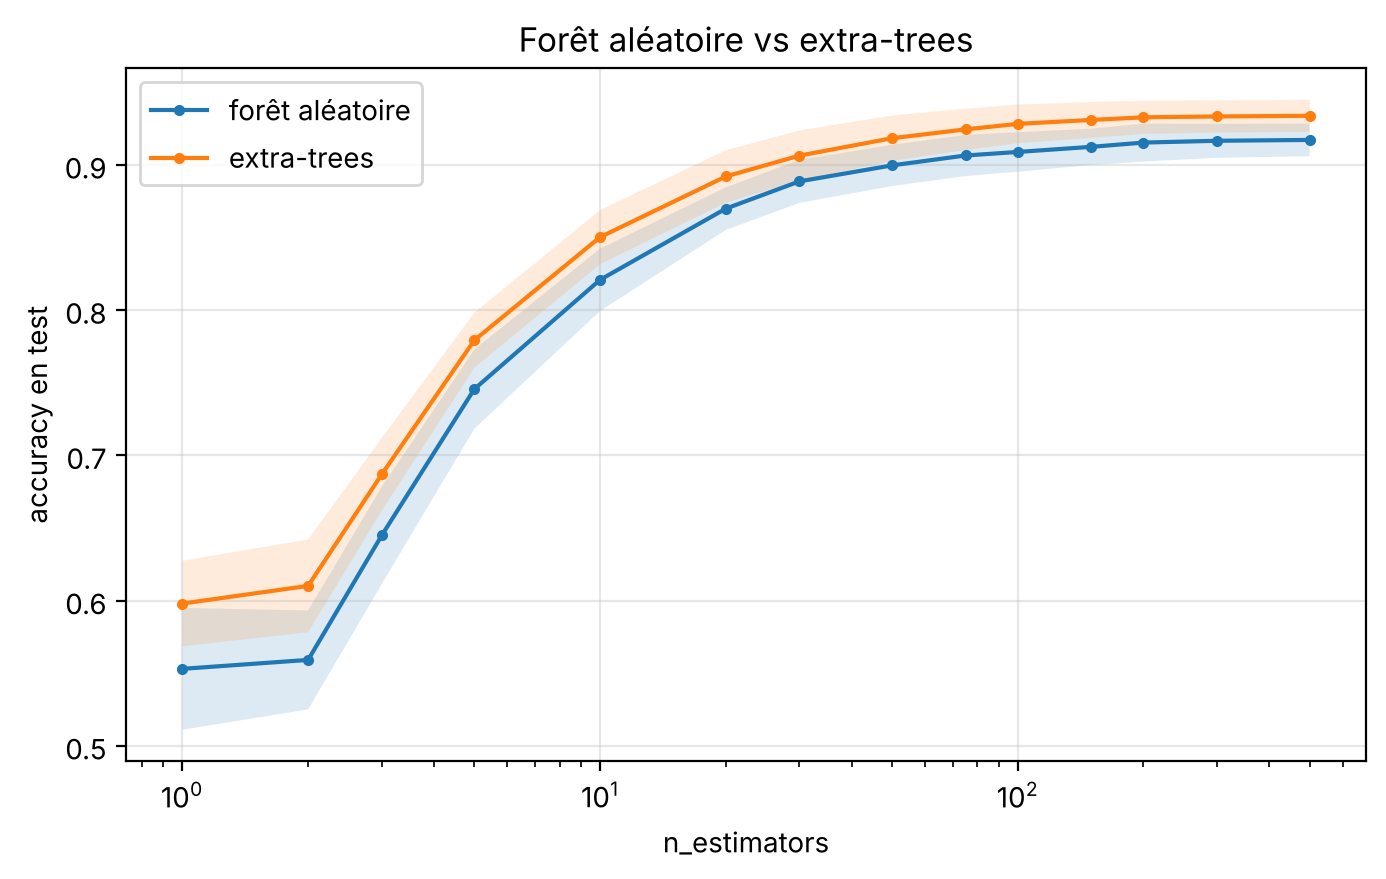

In [11]:
t0 = time.time()
acc_et = acc_sur_tirages(lambda s: ExtraTreesClassifier(n_estimators=200, random_state=s))
print(f"({time.time()-t0:.0f} s)")
display(pd.concat([resume(acc_rf, 'forêt aléatoire (200)'), resume(acc_et, 'extra-trees (200)')], axis=1).T)
diff = acc_et - acc_rf
print(f"Différence appariée extra-trees - forêt : moyenne = {diff.mean():+.4f}, extra-trees meilleurs dans {(diff > 0).sum()} tirages, égalité {(diff == 0).sum()}, moins bons {(diff < 0).sum()}")

# Temps d'entraînement sur une même base (10 % d'apprentissage, 200 arbres, 1 seul coeur)
for nom, M in (('forêt aléatoire', RandomForestClassifier), ('extra-trees', ExtraTreesClassifier)):
    t0 = time.time()
    for _ in range(5): M(n_estimators=200, random_state=0, n_jobs=1).fit(X_train, y_train)
    print(f"Temps d'apprentissage {nom:16s}: {(time.time()-t0)/5:.3f} s")

res_et = courbe_n_estimators(lambda s: ExtraTreesClassifier(random_state=s, warm_start=True), ns, n_tirages=20)
fig, ax = plt.subplots(figsize=(8, 4.5))
tracer_courbe(ax, ns, res_rf, "forêt aléatoire"); tracer_courbe(ax, ns, res_et, "extra-trees")
ax.set_xscale('log'); ax.set_xlabel("n_estimators"); ax.set_ylabel("accuracy en test"); ax.grid(alpha=.3); ax.legend()
ax.set_title("Forêt aléatoire vs extra-trees"); plt.show()

**Constat.** **ExtraTrees** (arbres extrêmement aléatoires) diffèrent de la forêt par deux points : les **seuils de découpage sont tirés au hasard** (au lieu de chercher le meilleur seuil) et, par défaut, **il n'y a pas de bootstrap** (chaque arbre voit tout l'échantillon d'apprentissage).
- Sur 100 tirages : extra-trees **93,0 %** (écart-type 1,23 point) contre **91,2 %** pour la forêt (1,47 point). Ils sont meilleurs dans **99 tirages sur 100** (+1,8 point en moyenne), et leur courbe en fonction de `n_estimators` est au-dessus de celle de la forêt.
- **Temps :** 0,17 s contre 0,20 s pour 200 arbres : légèrement plus rapide, l'écart est faible ici car la base est petite (en théorie, ils sont plus rapides car ils ne cherchent pas le meilleur seuil).
- **Interprétation (plausible, non testée ici) :** avec seulement 179 exemples, le régime est dominé par la variance ; la randomisation supplémentaire et l'absence de bootstrap la réduisent encore. Ce résultat est propre à ce régime de petit échantillon : sur de grandes bases, les deux méthodes sont généralement plus proches.

## Boosting (AdaBoost)
Exemple du sujet : 200 arbres de profondeur 5, `learning_rate=2`.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.90, random_state=0)
clf = AdaBoostClassifier(estimator=tree.DecisionTreeClassifier(max_depth=5), n_estimators=200, learning_rate=2, random_state=0)
clf.fit(X_train, y_train)
print("AdaBoost du sujet (profondeur 5, learning_rate=2, 200 arbres)")
print(f"  accuracy apprentissage = {clf.score(X_train, y_train):.4f}")
print(f"  accuracy test          = {clf.score(X_test, y_test):.4f}")
print(f"  nombre d'arbres effectivement construits : {len(clf.estimators_)}")

AdaBoost du sujet (profondeur 5, learning_rate=2, 200 arbres)
  accuracy apprentissage = 1.0000
  accuracy test          = 0.9240
  nombre d'arbres effectivement construits : 200


### Question — Effet de `max_depth`, `learning_rate` et du nombre de classifieurs

(13 s)


,acc. entraînement,test à 10 arbres,test à 50 arbres,test à 100 arbres,test à 200 arbres,arbres construits (moy.)
max_depth,,,,,,
1,0.8642,0.2540,0.5908,0.6957,0.7138,200.0
2,0.9983,0.5977,0.8129,0.8378,0.8522,200.0
3,1.0000,0.7337,0.8559,0.8779,0.8888,200.0
5,1.0000,0.8216,0.9046,0.9184,0.9226,200.0
10,0.9989,0.6864,0.6864,0.6864,0.6864,1.2
None,1.0000,0.6875,0.6875,0.6875,0.6875,1.0


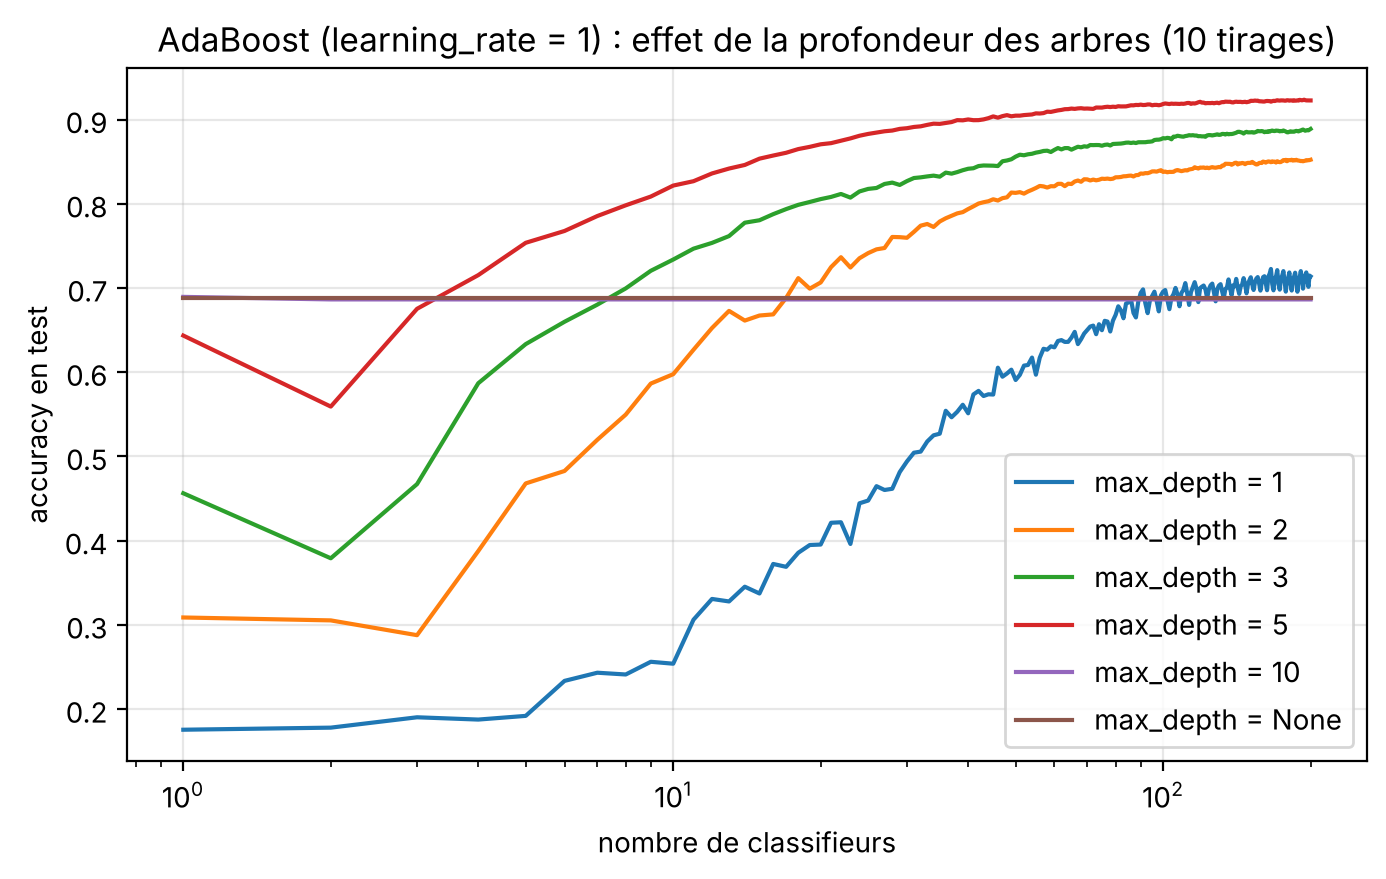

In [13]:
N_EST = 200
def courbe_boost(depth, lr, n_tirages=10):
    def un_tirage(seed):
        Xa, Xt, ya, yt = train_test_split(X, y, test_size=0.9, random_state=seed)
        m = AdaBoostClassifier(estimator=tree.DecisionTreeClassifier(max_depth=depth), n_estimators=N_EST,
                               learning_rate=lr, random_state=seed).fit(Xa, ya)
        sc = list(m.staged_score(Xt, yt))
        sc += [sc[-1]] * (N_EST - len(sc))      # si l'algorithme s'arrête avant (erreur nulle)
        return sc, m.score(Xa, ya), len(m.estimators_)
    out = Parallel(n_jobs=-1)(delayed(un_tirage)(s) for s in range(n_tirages))
    return np.array([o[0] for o in out]), np.mean([o[1] for o in out]), np.mean([o[2] for o in out])

t0 = time.time()
profondeurs = [1, 2, 3, 5, 10, None]
res_depth = {d: courbe_boost(d, 1.0) for d in profondeurs}
print(f"({time.time()-t0:.0f} s)")

rows = []
for d, (cv, tr, ne) in res_depth.items():
    rows.append({'max_depth': 'None' if d is None else d, 'acc. entraînement': tr,
                 **{f'test à {n} arbres': cv[:, n-1].mean() for n in (10, 50, 100, 200)},
                 'arbres construits (moy.)': ne})
display(pd.DataFrame(rows).set_index('max_depth'))

fig, ax = plt.subplots(figsize=(8, 4.5))
for d, (cv, tr, ne) in res_depth.items():
    ax.plot(range(1, N_EST + 1), cv.mean(0), label=f"max_depth = {d}")
ax.set_xscale('log'); ax.set_xlabel("nombre de classifieurs"); ax.set_ylabel("accuracy en test")
ax.set_title("AdaBoost (learning_rate = 1) : effet de la profondeur des arbres (10 tirages)")
ax.grid(alpha=.3); ax.legend(); plt.show()

(24 s)


,acc. entraînement,test à 10 arbres,test à 50 arbres,test à 100 arbres,test à 200 arbres
learning_rate,,,,,
0.01,1.0,0.6823,0.7896,0.8436,0.8724
0.05,1.0,0.7813,0.8744,0.8846,0.8933
0.10,1.0,0.8319,0.8875,0.8946,0.8973
0.50,1.0,0.8433,0.9004,0.9083,0.9133
1.00,1.0,0.8216,0.9046,0.9184,0.9226
2.00,1.0,0.7840,0.8951,0.9111,0.9193


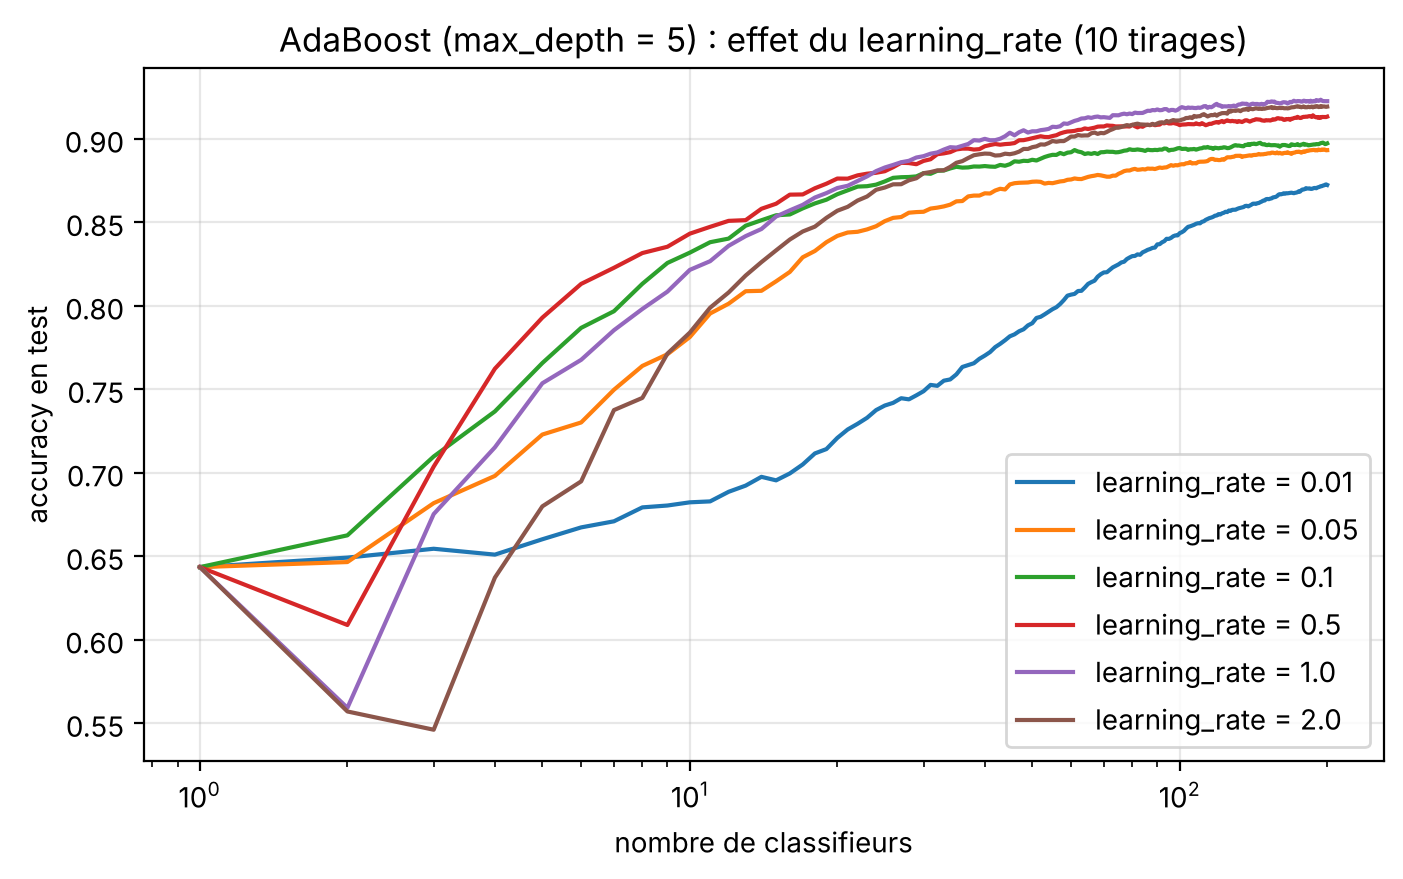

In [14]:
t0 = time.time()
taux = [0.01, 0.05, 0.1, 0.5, 1.0, 2.0]
res_lr = {lr: courbe_boost(5, lr) for lr in taux}
print(f"({time.time()-t0:.0f} s)")

rows = []
for lr, (cv, tr, ne) in res_lr.items():
    rows.append({'learning_rate': lr, 'acc. entraînement': tr,
                 **{f'test à {n} arbres': cv[:, n-1].mean() for n in (10, 50, 100, 200)}})
display(pd.DataFrame(rows).set_index('learning_rate'))

fig, ax = plt.subplots(figsize=(8, 4.5))
for lr, (cv, tr, ne) in res_lr.items():
    ax.plot(range(1, N_EST + 1), cv.mean(0), label=f"learning_rate = {lr}")
ax.set_xscale('log'); ax.set_xlabel("nombre de classifieurs"); ax.set_ylabel("accuracy en test")
ax.set_title("AdaBoost (max_depth = 5) : effet du learning_rate (10 tirages)")
ax.grid(alpha=.3); ax.legend(); plt.show()

**Exemple du sujet** (profondeur 5, `learning_rate = 2`, 200 arbres, 1 tirage) : accuracy test **92,4 %**, accuracy d'apprentissage 100 %.

**Effet de `max_depth`** (`learning_rate = 1`, moyenne de 10 tirages) :
- **Classifieur trop faible** (`max_depth = 1`, des « souches ») : 25 % à 10 arbres, **71,4 % à 200 arbres** et encore en progression ; l'accuracy d'apprentissage n'est que de 86 % : il y a sous-apprentissage et il faudrait beaucoup plus de classifieurs. Profondeur 2 : 85,2 % ; profondeur 3 : 88,9 %.
- **Profondeur 5 : meilleur résultat, 92,3 %** à 200 arbres (82,2 % à 10 arbres, 90,5 % à 50, 91,8 % à 100).
- **Classifieur trop fort** (`max_depth = 10` ou `None`) : l'**AdaBoost s'arrête dès le premier arbre** (1,0 à 1,2 arbres construits en moyenne), car celui-ci classe parfaitement l'apprentissage, l'erreur pondérée est nulle et il n'y a rien à corriger. On retrouve la performance d'un arbre seul (**68,6 %**) : le boosting a besoin de classifieurs **faibles**, pas de classifieurs qui sur-apprennent.

**Effet de `learning_rate`** (profondeur 5, 200 arbres) :
- Un **très petit taux** apprend lentement (0,01 : 87,2 % à 200 arbres, encore en progression ; 0,1 : 89,7 %). Un petit taux demande beaucoup plus d'arbres : il y a un compromis entre `learning_rate` et `n_estimators`.
- Les valeurs **0,5 à 1** sont les meilleures (91,3 % à 92,3 %) ; **2** (valeur de l'exemple) reste correct (91,9 %) mais un peu moins bon et plus instable au début (78,4 % à 10 arbres contre 82,2 % pour 1).

**Effet du nombre de classifieurs :** pour les bons réglages, l'accuracy de test continue à **augmenter légèrement** entre 100 et 200 arbres (91,8 % → 92,3 % pour `learning_rate = 1`) alors que l'erreur d'apprentissage est déjà nulle : pas de surapprentissage visible ici.

*Ordre de grandeur, à comparer avec les autres méthodes dans le même régime (10 % d'apprentissage) :* AdaBoost bien réglé ≈ 92 %, forêt aléatoire ≈ 91 %, extra-trees ≈ 93 %, bagging ≈ 88 % (AdaBoost sur 10 tirages, les autres sur 100).

---
# Partie II — Utilisation de Python
## Exercice 1 — Forêt aléatoire sur les données Iris

apprentissage : (105, 4) | test : (45, 4)


Accuracy apprentissage : 1.0000
Score OOB (out-of-bag) : 0.9333   -> estimation de l'erreur de généralisation sans jeu de test
Accuracy test          : 0.9778

Matrice de confusion (test) :
[[15  0  0]
 [ 0 15  0]
 [ 0  1 14]]
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      0.938     1.000     0.968        15
   virginica      1.000     0.933     0.966        15

    accuracy                          0.978        45
   macro avg      0.979     0.978     0.978        45
weighted avg      0.979     0.978     0.978        45



Validation croisée 10 plis : forêt 0.9600 ± 0.0442 | arbre seul 0.9600 ± 0.0442


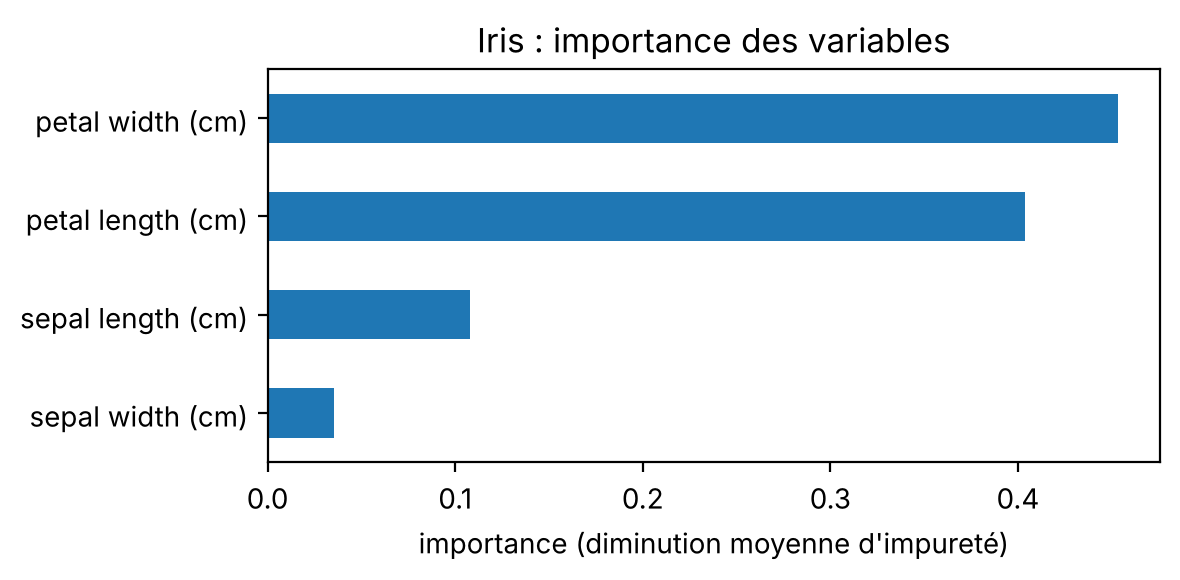

petal width (cm)     0.453
petal length (cm)    0.404
sepal length (cm)    0.108
sepal width (cm)     0.035
dtype: float64


In [15]:
iris = load_iris()
Xi, yi = iris.data, iris.target
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, test_size=0.3, random_state=0, stratify=yi)
print("apprentissage :", Xi_tr.shape, "| test :", Xi_te.shape)

rf_i = RandomForestClassifier(n_estimators=200, oob_score=True, random_state=0).fit(Xi_tr, yi_tr)
print(f"Accuracy apprentissage : {rf_i.score(Xi_tr, yi_tr):.4f}")
print(f"Score OOB (out-of-bag) : {rf_i.oob_score_:.4f}   -> estimation de l'erreur de généralisation sans jeu de test")
print(f"Accuracy test          : {rf_i.score(Xi_te, yi_te):.4f}")

print("\nMatrice de confusion (test) :")
print(confusion_matrix(yi_te, rf_i.predict(Xi_te)))
print(classification_report(yi_te, rf_i.predict(Xi_te), target_names=iris.target_names, digits=3))

# Comparaison par validation croisée 10 plis sur l'ensemble des 150 exemples
cv_rf = cross_val_score(RandomForestClassifier(n_estimators=200, random_state=0), Xi, yi, cv=10)
cv_dt = cross_val_score(tree.DecisionTreeClassifier(random_state=0), Xi, yi, cv=10)
print(f"Validation croisée 10 plis : forêt {cv_rf.mean():.4f} ± {cv_rf.std():.4f} | arbre seul {cv_dt.mean():.4f} ± {cv_dt.std():.4f}")

imp = pd.Series(rf_i.feature_importances_, index=iris.feature_names).sort_values()
plt.figure(figsize=(6, 3)); imp.plot.barh(); plt.xlabel("importance (diminution moyenne d'impureté)")
plt.title("Iris : importance des variables"); plt.tight_layout(); plt.show()
print(imp.sort_values(ascending=False).round(3))

**Commentaire.**
- **Accuracy test : 97,8 %** (44 images bien classées sur 45 : une *virginica* prédite *versicolor*). **Score OOB : 93,3 %** et **validation croisée 10 plis : 96,0 % ± 4,4 points** : trois estimations de la même performance de généralisation, un peu différentes car chacune est bruitée (avec 45 exemples de test, 1 fleur = 2,2 points).
- ***setosa*** est parfaitement reconnue ; les seules confusions concernent *versicolor* et *virginica*.
- **Importance des variables :** largeur du pétale (0,45) et longueur du pétale (0,40) portent **86 %** de l'importance, contre 0,11 pour la longueur du sépale et 0,04 pour la largeur du sépale : ce sont les pétales qui discriminent les espèces (cohérent avec les TP précédents).
- **La forêt ne fait pas mieux qu'un arbre seul ici** : en validation croisée, les deux commettent **6 erreurs sur 150** (96,0 % chacun, pas exactement sur les mêmes fleurs). Iris est petit et facile : les méthodes d'ensemble n'ont presque rien à gagner, contrairement à Digits avec peu d'exemples.

## Exercice 2 — Forêt aléatoire sur MNIST
> Par défaut (`USE_FULL_MNIST = False`) on utilise la base **Digits de scikit-learn** (1797 images 8×8), version réduite de MNIST utilisée dans les TP précédents. Pour la vraie base MNIST (70 000 images 28×28, téléchargement depuis OpenML), mettre `USE_FULL_MNIST = True` : l'entraînement dure alors quelques dizaines de secondes à quelques minutes et les valeurs ci-dessous seront différentes.

In [16]:
USE_FULL_MNIST = False

if USE_FULL_MNIST:
    from sklearn.datasets import fetch_openml
    mn = fetch_openml('mnist_784', version=1, as_frame=False)
    Xm, ym = mn.data / 255.0, mn.target.astype(int)
    Xm_tr, Xm_te, ym_tr, ym_te = Xm[:60000], Xm[60000:], ym[:60000], ym[60000:]
    nom_base = "MNIST (60 000 / 10 000)"
else:
    Xm, ym = digits.data, digits.target
    Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.2, random_state=0, stratify=ym)
    nom_base = "Digits (80 % / 20 %)"
print(nom_base, "| apprentissage :", Xm_tr.shape, "| test :", Xm_te.shape)

t0 = time.time()
rf_m = RandomForestClassifier(n_estimators=200, oob_score=True, n_jobs=-1, random_state=0).fit(Xm_tr, ym_tr)
print(f"Temps d'apprentissage : {time.time()-t0:.1f} s")
print(f"Accuracy apprentissage : {rf_m.score(Xm_tr, ym_tr):.4f}")
print(f"Score OOB              : {rf_m.oob_score_:.4f}")
pred_m = rf_m.predict(Xm_te)
print(f"Accuracy test          : {(pred_m == ym_te).mean():.4f}")

dt_m = tree.DecisionTreeClassifier(random_state=0).fit(Xm_tr, ym_tr)
print(f"(Arbre seul : test = {dt_m.score(Xm_te, ym_te):.4f})")

Digits (80 % / 20 %) | apprentissage : (1437, 64) | test : (360, 64)


Temps d'apprentissage : 0.4 s
Accuracy apprentissage : 1.0000
Score OOB              : 0.9749
Accuracy test          : 0.9778
(Arbre seul : test = 0.8778)


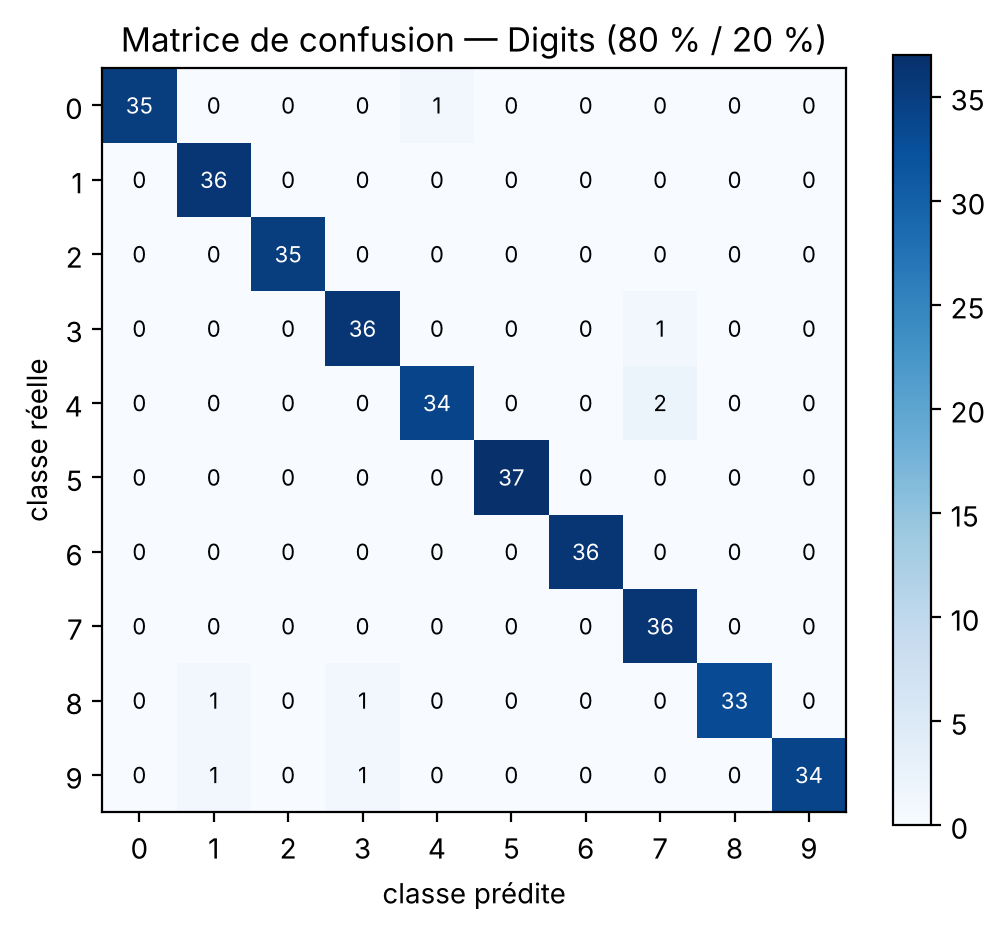

              precision    recall  f1-score   support

           0      1.000     0.972     0.986        36
           1      0.947     1.000     0.973        36
           2      1.000     1.000     1.000        35
           3      0.947     0.973     0.960        37
           4      0.971     0.944     0.958        36
           5      1.000     1.000     1.000        37
           6      1.000     1.000     1.000        36
           7      0.923     1.000     0.960        36
           8      1.000     0.943     0.971        35
           9      1.000     0.944     0.971        36

    accuracy                          0.978       360
   macro avg      0.979     0.978     0.978       360
weighted avg      0.979     0.978     0.978       360

Confusions les plus fréquentes (réel -> prédit : nombre) : [('4->7', 2), ('0->4', 1), ('3->7', 1), ('8->1', 1), ('8->3', 1)]


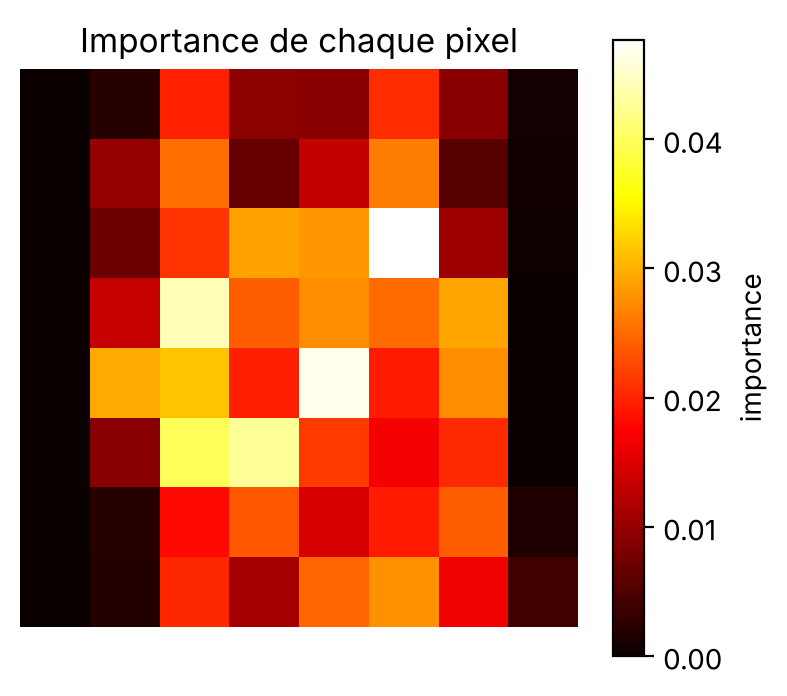

In [17]:
cm = confusion_matrix(ym_te, pred_m)
plt.figure(figsize=(6, 5)); plt.imshow(cm, cmap='Blues'); plt.colorbar()
plt.xticks(range(10)); plt.yticks(range(10)); plt.xlabel("classe prédite"); plt.ylabel("classe réelle")
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha='center', va='center', color='w' if cm[i, j] > cm.max()/2 else 'k', fontsize=8)
plt.title(f"Matrice de confusion — {nom_base}"); plt.show()
print(classification_report(ym_te, pred_m, digits=3))

hors = cm.copy(); np.fill_diagonal(hors, 0)
couples = sorted([(i, j, hors[i, j]) for i in range(10) for j in range(10) if hors[i, j] > 0], key=lambda t: -t[2])
print("Confusions les plus fréquentes (réel -> prédit : nombre) :", [(f"{i}->{j}", int(n)) for i, j, n in couples[:5]])

# Importance des pixels
cote = int(np.sqrt(Xm.shape[1]))
plt.figure(figsize=(4.5, 4)); plt.imshow(rf_m.feature_importances_.reshape(cote, cote), cmap='hot')
plt.colorbar(label='importance'); plt.title("Importance de chaque pixel"); plt.axis('off'); plt.show()

In [18]:
# Effet de max_features et de n_estimators sur cette base
rows = []
for mf in ['sqrt', 'log2', 0.1, 0.3, 0.5, 1.0]:
    m = RandomForestClassifier(n_estimators=200, max_features=mf, oob_score=True, n_jobs=-1, random_state=0).fit(Xm_tr, ym_tr)
    rows.append({'max_features': mf, 'OOB': m.oob_score_, 'test': m.score(Xm_te, ym_te)})
display(pd.DataFrame(rows).set_index('max_features'))

ns2 = [1, 5, 10, 25, 50, 100, 200, 400]
m = RandomForestClassifier(random_state=0, warm_start=True, n_jobs=-1)
sc = []
for n in ns2:
    m.set_params(n_estimators=n); m.fit(Xm_tr, ym_tr); sc.append(m.score(Xm_te, ym_te))
display(pd.DataFrame({'n_estimators': ns2, 'accuracy test': sc}).set_index('n_estimators').T)

,OOB,test
max_features,,
sqrt,0.9749,0.9778
log2,0.9743,0.9667
0.1,0.9743,0.9667
0.3,0.9729,0.9778
0.5,0.9673,0.9778
1.0,0.9527,0.9583


n_estimators,1,5,10,25,50,100,200,400
accuracy test,0.7583,0.8806,0.9306,0.95,0.9667,0.9806,0.9778,0.975


**Commentaire** (base Digits par défaut, voir la remarque ci-dessus).
- **Forêt de 200 arbres : accuracy test 97,8 %** (352 images sur 360), accuracy d'apprentissage 100 %, contre **87,8 %** pour un arbre seul. Le **score OOB (97,5 %) est très proche du score de test** : l'estimation *out-of-bag* donne gratuitement une bonne idée de l'erreur de généralisation, sans réserver de jeu de test.
- Les erreurs sont peu nombreuses et dispersées (la plus fréquente : un **4 prédit 7**, 2 fois ; les autres confusions ne se produisent qu'une fois).
- **Importance des pixels :** les pixels du **centre** de l'image sont les plus utiles ; ceux du **bord** (surtout la première colonne, quasi toujours à 0 dans les données) ont une importance quasi nulle.
- **`max_features` :** `'sqrt'` (8 variables par nœud) donne 97,8 % (OOB 97,5 %) ; utiliser **toutes** les variables (ce qui revient à du bagging d'arbres) donne 95,8 % (OOB 95,3 %) : le tirage de variables apporte environ **2 points**, comme dans la Partie I.
- **`n_estimators` :** 75,8 % avec 1 arbre, 93,1 % avec 10, 95,0 % avec 25, 96,7 % avec 50, puis **palier à partir de ≈ 100 arbres** (98,1 % ; 97,8 % ; 97,5 % : les petites variations, ≈ 1 image sur 360, sont du bruit).
- Avec 80 % des données pour l'apprentissage (au lieu de 10 %), la forêt atteint 97,8 % contre 91,2 % dans la Partie I : la quantité de données d'apprentissage compte beaucoup.

---
# Synthèse
**Régime du sujet (Digits, 10 % pour l'apprentissage, 100 tirages sauf indication) :**

| méthode | accuracy moyenne en test | écart-type |
|---|---|---|
| arbre seul | 68,9 % | 3,0 points |
| bagging (200 arbres) | 87,5 % | 2,0 points |
| forêt aléatoire (200 arbres) | 91,2 % | 1,5 points |
| extra-trees (200 arbres) | 93,0 % | 1,2 points |
| AdaBoost (profondeur 5, `learning_rate` = 1, 200 arbres ; 10 tirages) | ≈ 92,3 % | — |

- Les méthodes d'ensemble **réduisent fortement la variance** de l'arbre de décision et améliorent la précision de **18 à 24 points** dans ce régime de petit échantillon.
- **Bagging → forêt aléatoire** : la randomisation des variables à chaque nœud décorrèle les arbres ; le nombre d'arbres n'est pas critique au-delà de ≈ 100–200 (pas de surapprentissage).
- **Boosting** : très sensible au choix du classifieur faible (profondeur 5 ici ; une souche est trop faible, un arbre profond fait arrêter l'algorithme) et au couple `learning_rate` / `n_estimators`.
- **Iris** est trop simple pour distinguer ces méthodes ; sur **Digits** avec beaucoup de données, la forêt atteint ≈ 98 %.